<a href="https://colab.research.google.com/github/roberthsu2003/machine_learning/blob/main/%E5%90%8D%E8%A9%9E%E8%A7%A3%E9%87%8B/10_%E6%A8%A1%E5%9E%8B%E6%80%A7%E8%83%BD%E5%95%8F%E9%A1%8C/README.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 10. 模型性能問題 (Underfitting vs Overfitting)

模型性能問題光譜：
- **欠擬合 (Underfitting)**：模型太死板（高偏差），如一條直線無法擬合彎曲週期。
- **良好擬合 (Good Fit)**：抓住真實規律，具備優秀泛化能力。
- **過度擬合 (Overfitting)**：模型太自由（高方差），把每一個雜訊噪點死記硬背。

本範例讀取「季節銷售趨勢資料集」，繪圖展示三種多項式複雜度的擬合對比！

In [1]:
%%capture
%pip install mplfonts seaborn scikit-learn pandas numpy matplotlib


In [2]:
# --- 設定 Matplotlib / Seaborn 中文字型支援（Mac / Windows / Colab 通用）---
import glob
import os
import mplfonts
from matplotlib import font_manager
import matplotlib.pyplot as plt
import seaborn as sns
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)
use_font("Noto Sans CJK SC")
plt.rcParams['axes.unicode_minus'] = False
print("繁體中文字型已成功載入！")


繁體中文字型已成功載入！


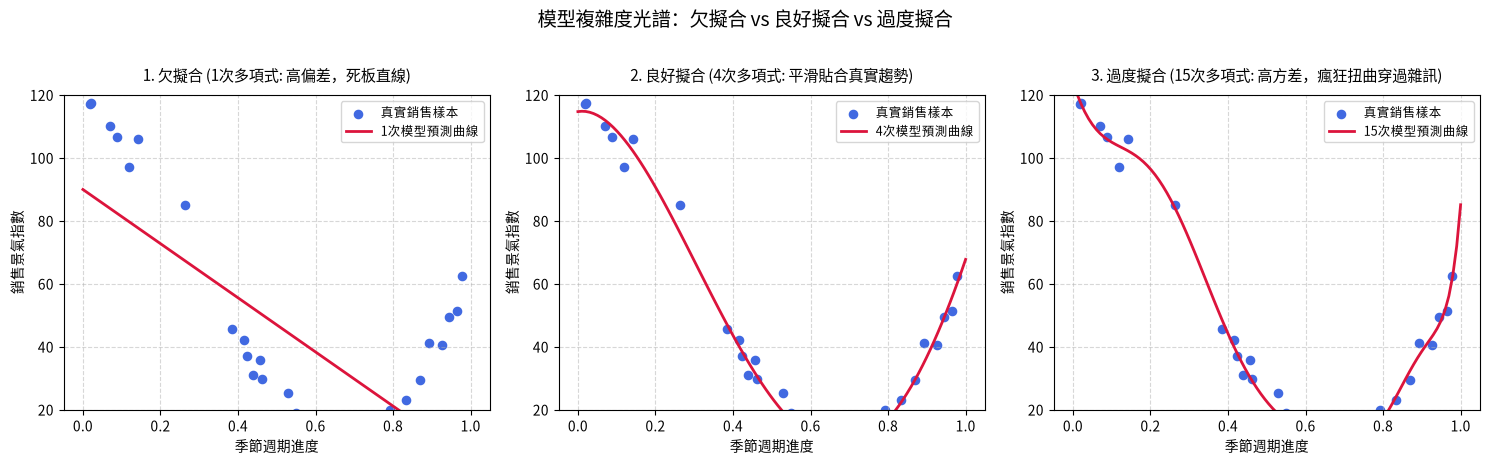

💡 觀念總結：模型並非越複雜越好，適當約束模型自由度才能確保面對未知數據時的穩定性！


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# 讀取季節銷售資料集
df = pd.read_csv('季節銷售趨勢資料集.csv')
X = df[['季節週期進度']].values
y = df['銷售景氣指數'].values

X_plot = np.linspace(0, 1, 100)[:, np.newaxis]

degrees = [1, 4, 15]
titles = [
    '1. 欠擬合 (1次多項式: 高偏差，死板直線)', 
    '2. 良好擬合 (4次多項式: 平滑貼合真實趨勢)', 
    '3. 過度擬合 (15次多項式: 高方差，瘋狂扭曲穿過雜訊)'
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for i, degree in enumerate(degrees):
    ax = axes[i]
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    model.fit(X, y)
    
    ax.scatter(X, y, color='royalblue', s=35, label='真實銷售樣本')
    ax.plot(X_plot, model.predict(X_plot), color='crimson', linewidth=2, label=f'{degree}次模型預測曲線')
    ax.set_title(titles[i], fontsize=11, pad=10)
    ax.set_xlabel('季節週期進度', fontsize=10)
    ax.set_ylabel('銷售景氣指數', fontsize=10)
    ax.set_ylim((20, 120))
    ax.legend(fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('模型複雜度光譜：欠擬合 vs 良好擬合 vs 過度擬合', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("💡 觀念總結：模型並非越複雜越好，適當約束模型自由度才能確保面對未知數據時的穩定性！")
